> # HW 11 - Charlie Caravati

In [57]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.special as sp
from scipy.integrate import quad
import numpy.polynomial.laguerre as lag

> ## 1.

$I-I_n = \frac{C_1}{n^{3/2}} + \frac{C_2}{n^2}+ \frac{C_3}{n^{5/2}} + \frac{C_4}{n^3} + O(\frac{1}{n^{7/2}})$

Generalize Richardson to obtain an estimate of $I$ with an error of order $\frac{1}{n^2\sqrt{n}} = \frac{1}{n^3/2}$.

$I-I_{n/2} = \frac{C_1}{(n/2)^{3/2}} + \frac{C_2}{(n/2)^2}+ \frac{C_3}{(n/2)^{5/2}} + \frac{C_4}{(n/2)^3} + ... = \frac{2\sqrt{2}C_1}{n^{3/2}} + \frac{4C_2}{n^2}+ \frac{4\sqrt{2}C_3}{n^{5/2}} + O(\frac{1}{n^{7/2}})$

$I-I_{n/4} = \frac{C_1}{(n/4)^{3/2}} + \frac{C_2}{(n/4)^2}+ \frac{C_3}{(n/4)^{5/2}} + \frac{C_4}{(n/4)^3} + ... = \frac{8C_1}{n^{3/2}} + \frac{16C_2}{n^2}+ \frac{32C_3}{n^{5/2}} + O(\frac{1}{n^{7/2}})$

$2\sqrt{2}(I-I_n) - (I-I_{n/2}) = (2\sqrt{2} - 4)\frac{C_2}{n^2} + O(\frac{1}{n^{5/2}})$

$(2\sqrt{2} - 1)I - (2\sqrt{2}I_n - I_{n/2}) = (2\sqrt{2} - 4)\frac{C_2}{n^2} + O(\frac{1}{n^{5/2}})$

$I - \frac{(2\sqrt{2}I - I_{n/2})}{(2\sqrt{2} - 1)} = (\frac{2\sqrt{2} - 4}{2\sqrt{2} - 1})\frac{C_2}{n^2} + O(\frac{1}{n^{5/2}})$

Let $J_1 = \frac{(2\sqrt{2}I_n - I_{n/2})}{(2\sqrt{2} - 1)}$ then $I - J_1 = (\frac{2\sqrt{2} - 4}{2\sqrt{2} - 1})\frac{C_2}{n^2} + O(\frac{1}{n^{5/2}}) = \frac{D_2}{n^2} + O(\frac{1}{n^{5/2}})$

$2\sqrt{2}(I-I_{n/2}) - (I-I_{n/4}) = (8\sqrt{2}-16)\frac{C_2}{n^2} + O(\frac{1}{n^{5/2}})$

$(2\sqrt{2} - 1)I - (2\sqrt{2}I_{n/2} - I_{n/4}) = (8\sqrt{2}-16)\frac{C_2}{n^2} + O(\frac{1}{n^{5/2}})$

$I - \frac{2\sqrt{2}I_{n/2} - I_{n/4}}{2\sqrt{2} - 1} = (\frac{8\sqrt{2}-16}{2\sqrt{2} - 1})\frac{C_2}{n^2} + O(\frac{1}{n^{5/2}})$

Let $J_2 = \frac{2\sqrt{2}I_{n/2} - I_{n/4}}{2\sqrt{2} - 1}$ then $I - J_2 = 4(\frac{2\sqrt{2}-4}{2\sqrt{2} - 1})\frac{C_2}{n^2} + O(\frac{1}{n^{5/2}}) = \frac{4D_2}{n^2} + O(\frac{1}{n^{5/2}})$

Then $4(I-J_1) - (I-J_2)$ cancels out the $\frac{D_2}{n^2}$ term and gives $(4-1)I - (4J_1-J_2) = 3I - (4J_1-J_2)$ with only $O(\frac{1}{n^{5/2}})$ terms leading.

Then gives $I = \frac{4J_1-J_2}{3} + O(\frac{1}{n^{5/2}})$








> ## 2. 

> (a)

$I - I(h) = c_1h^4 + c_2h^6 + c_3h^8+c_4h^{10}+...$

$I - I(h/2) = c_1{(h/2)}^4 + c_2{(h/2)}^6 + c_3{(h/2)}^8+... = \frac{c_1h^4}{16} + \frac{c_2h^6}{64} + \frac{c_3h^8}{256}$

$16(I - I(h/2)) - (I-I(h)) = (\frac{1}{4} - 1)c_2h^4 + O(h^8) = -\frac{3}{4}c_2h^6 + O(h^8)$

$15I - 16I(h/2) + I(h) = O(h^6)$

$I = \frac{16I(h/2) - I(h)}{15} + O(h^6)$

Then $R(h) = \frac{16I(h/2) - I(h)}{15}$ with error $O(h^6)$ instead the standard $O(h^4)$.


absolute error in column 0 =  [4.29203673e-01 1.03881102e-01 2.57683981e-02 6.42965623e-03
 1.60663903e-03 4.01611360e-04]
absolute error in column 1 =  [4.55975498e-03 2.69169948e-04 1.65910479e-05 1.03336941e-06
 6.45300018e-08]
absolute error in column 2 =  [1.68690540e-05 2.47545428e-07 3.80915499e-09 5.92923488e-11]
absolute error in column 3 =  [1.62880411e-08 5.96749317e-11 2.29150032e-13]
absolute error in column 4 =  [3.96571664e-12 3.99680289e-15]
absolute error in column 5 =  [2.22044605e-16]
absolute error of best approximation at each order =  [4.29203673e-01 4.55975498e-03 1.68690540e-05 1.62880411e-08
 3.96571664e-12 2.22044605e-16]


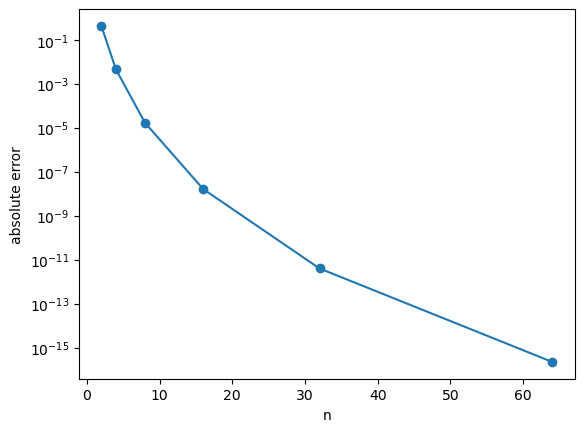

In [ ]:
def driver():

    f = lambda x: np.sin(x)
    a = 0
    b = np.pi

    # exact integral
    I_ex = 2

    nrefine = 6

# number of panels: 1, 2, 4, ..., 2^nrefine
    ntest = 2**np.arange(1,nrefine+1)

    Rom = rombergTrap(a,b,nrefine,f)

# column j is only filled from row j down
    for j in range(0,nrefine):
        print('absolute error in column', j, '= ', abs(I_ex-Rom[j:,j]))

    err = abs(I_ex-np.diag(Rom))

    print('absolute error of best approximation at each order = ', err)

    plt.semilogy(ntest,err,'o-')
    plt.xlabel('n')
    plt.ylabel('absolute error')
    plt.show()


def rombergTrap(a,b,nrefine,f):
# number of panels: 1, 2, 4, ..., 2^nrefine
    ntest = 2**np.arange(1,nrefine+1)

    nn = len(ntest)

    Rom = np.zeros((nn,nn))

# first column: composite trapezoidal rule with n panels
    for j in range(0,nn):
        Rom[j,0] = CompTrap(a,b,ntest[j],f)

# remaining columns: Richardson extrapolation
    for j in range(1,nn):
        for i in range(j,nn):
            Rom[i,j] = Rom[i,j-1] + (Rom[i,j-1]-Rom[i-1,j-1])/(4**j-1)

    return Rom


def CompTrap(a,b,n,f):
    h = (b-a)/n
    xnode = a+np.arange(0,n+1)*h

    I_trap = h*f(xnode[0])*1/2

    for j in range(1,n):
         I_trap = I_trap+h*f(xnode[j])
    I_trap= I_trap + 1/2*h*f(xnode[n])

    return I_trap




driver()


absolute error in column 0 =  [9.43951024e-02 4.55975498e-03 2.69169948e-04 1.65910479e-05
 1.03336941e-06 6.45300018e-08]
absolute error in column 1 =  [1.42926818e-03 1.68690540e-05 2.47545428e-07 3.80915544e-09
 5.92923488e-11]
absolute error in column 2 =  [1.13302339e-05 1.82363041e-07 2.85332691e-09 4.45870008e-11]
absolute error in column 3 =  [1.79640729e-07 2.80949064e-09 4.39011050e-11]
absolute error in column 4 =  [2.80679235e-09 4.38589165e-11]
absolute error in column 5 =  [4.3856252e-11]
absolute error of best approximation at each order =  [9.43951024e-02 1.42926818e-03 1.13302339e-05 1.79640729e-07
 2.80679235e-09 4.38562520e-11]


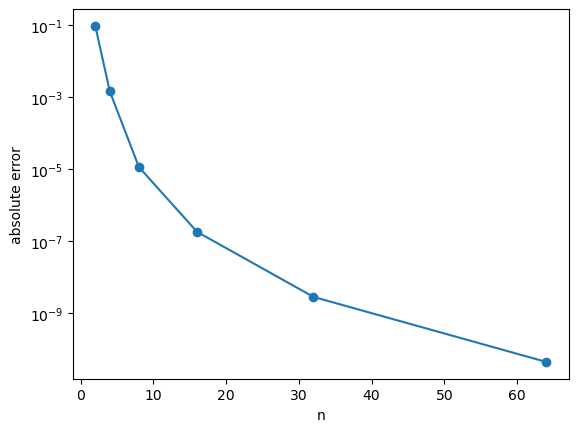

In [23]:
def driver():

    f = lambda x: np.sin(x)
    a = 0
    b = np.pi

    # exact integral
    I_ex = 2

    nrefine = 6

# number of panels: 1, 2, 4, ..., 2^nrefine
    ntest = 2**np.arange(1,nrefine+1)

    Rom = rombergSimp(a,b,nrefine,f)

# column j is only filled from row j down
    for j in range(0,nrefine):
        print('absolute error in column', j, '= ', abs(I_ex-Rom[j:,j]))

    err = abs(I_ex-np.diag(Rom))

    print('absolute error of best approximation at each order = ', err)

    plt.semilogy(ntest,err,'o-')
    plt.xlabel('n')
    plt.ylabel('absolute error')
    plt.show()


def rombergSimp(a,b,nrefine,f):
# number of panels: 1, 2, 4, ..., 2^nrefine
    ntest = 2**np.arange(1,nrefine+1)

    nn = len(ntest)

    Rom = np.zeros((nn,nn))

# first column: composite trapezoidal rule with n panels
    for j in range(0,nn):
        Rom[j,0] = CompSimp(a,b,ntest[j],f)

# remaining columns: Richardson extrapolation
    for j in range(1,nn):
        for i in range(j,nn):
            Rom[i,j] = Rom[i,j-1] + (Rom[i,j-1]-Rom[i-1,j-1])/(16**j-1)

    return Rom

def CompSimp(a, b, M, f):

    if np.remainder(M,2)!=0:
        M = M-1
        message = "M must be even, calculating with M-1"
    else:
        message = None
    h = (b - a) / M
    x = np.linspace(a, b, M + 1)
    y = f(x)
    integral = (h / 3) * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-1:2]) + y[-1])
    return integral


driver()


Romberg-Trapezoid gives "absolute error of best approximation at each order =  [4.29203673e-01 4.55975498e-03 1.68690540e-05 1.62880411e-08 3.96571664e-12 2.22044605e-16]"

Romberg-Simpsons gives "absolute error of best approximation at each order =  [9.43951024e-02 1.42926818e-03 1.13302339e-05 1.79640729e-07 2.80679235e-09 4.38562520e-11]" 

Simpson's is immediately better that Trapezoid but suffers at higher orders due to catastrophic cancellation in numerator terms.

> ## 3.

$t=\frac{1}{x} \to x=\frac{1}{t}$

$dx = -\frac{1}{t^2}dt$

$\int_1^{\infty} \frac{cos(x)}{x^3} dx = \int_1^{0} \frac{cos(1/t)}{(1/t)^3} (-\frac{1}{t^2}) dt = \int_0^{1} cos(1/t)(\frac{t^3}{t^2}) dt = \int_0^{1} (t)cos(1/t) dt$

In [ ]:
def CompSimp(a, b, M, f):

    if np.remainder(M,2)!=0:
        M = M-1
        message = "M must be even, calculating with M-1"
    else:
        message = None
    h = (b - a) / M
    x = np.linspace(a, b, M + 1)
    y = f(x)
    integral = (h / 3) * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-1:2]) + y[-1])
    return integral

In [33]:
a = 0
b = 1
# 4 intervals gives 5 nodes
M = 4
f = lambda t: np.where(t==0, 0, t*np.cos(1/t))

int_appx = CompSimp(a, b, M, f)

print(f"The integral approximation is {int_appx}")

The integral approximation is 0.014685380697196136


/var/folders/nm/zhg7jf3n4gz76nqmv2nbzvrr0000gn/T/ipykernel_1389/2546437955.py:5: RuntimeWarning: divide by zero encountered in divide
  f = lambda t: np.where(t==0, 0, t*np.cos(1/t))
/var/folders/nm/zhg7jf3n4gz76nqmv2nbzvrr0000gn/T/ipykernel_1389/2546437955.py:5: RuntimeWarning: invalid value encountered in cos
  f = lambda t: np.where(t==0, 0, t*np.cos(1/t))


The errors come from dividing by 0 when t=0 which is successfully dropped by np.where which gives our integral approximation of 0.014685380697196136 which is very close to an online solver approximation of 0.0181176 especially given only 5 nodes.

> # 4.

In [47]:
def driver():
     x_vals = [2, 4, 6, 8, 10]

     trunc = 40
     M = 500

     for x in x_vals:
          f = lambda t: (t**(x-1)) * np.exp(-t)

          appx = CompTrap(0, trunc, M, f)
          exact = sp.gamma(x)
          rel_err = abs(appx-exact) / exact

          print(f"For x={x}, the integral approximation is {appx} w/ relative error {rel_err}")


def CompTrap(a,b,n,f):
    h = (b-a)/n
    xnode = a+np.arange(0,n+1)*h

    I_trap = h*f(xnode[0])*1/2

    for j in range(1,n):
         I_trap = I_trap+h*f(xnode[j])
    I_trap= I_trap + 1/2*h*f(xnode[n])

    return I_trap

driver()

For x=2, the integral approximation is 0.999466837289998 w/ relative error 0.0005331627100020331
For x=4, the integral approximation is 6.000000340813211 w/ relative error 5.6802201905033676e-08
For x=6, the integral approximation is 119.99999999846774 w/ relative error 1.276880823297688e-11
For x=8, the integral approximation is 5039.999999161047 w/ relative error 1.664590046049044e-10
For x=10, the integral approximation is 362879.99857489683 w/ relative error 3.927202292777946e-09


I chose my truncation and interval values through experimentation and did not notice much tradeoff in computation time for relatively similar values. That relative error is still so small when the true answer increases to 9! is a solid indicator of high accuracy. 

In [64]:
def driver():
     x_vals = [2, 4, 6, 8, 10]

     for x in x_vals:
          f = lambda t: (t**(x-1)) * np.exp(-t)

          appx, _, infodict = quad(f, 0, np.inf, full_output=True)
          exact = sp.gamma(x)
          rel_err = abs(appx-exact) / exact

          print(f"For x={x}, the integral approximation is {appx} w/ {infodict['neval']} computations and relative error {rel_err}")


driver()

For x=2, the integral approximation is 0.9999999999999998 w/ 135 computations and relative error 2.220446049250313e-16
For x=4, the integral approximation is 6.0 w/ 165 computations and relative error 0.0
For x=6, the integral approximation is 120.00000000000001 w/ 165 computations and relative error 1.1842378929335003e-16
For x=8, the integral approximation is 5040.000000000001 w/ 195 computations and relative error 1.804552979708191e-16
For x=10, the integral approximation is 362879.99999999994 w/ 225 computations and relative error 1.6040470930739476e-16


The built in quad function approximates the interval with near machine-precision and significantly fewer computations than composite trapezoid, which can vary. All x values had less than 200 calculations for the built in quad but there are M+1 calculations for each composite trapezoid run, which gives 501 calculations for lower accuracy.

In [63]:
def driver():
     x_vals = [2, 4, 6, 8, 10]

     # when x=10, order is t^9, which is approximated exactly by order 2n-1
     n=5

     x_nodes, weights = lag.laggauss(n)

     for x in x_vals:
          f = lambda t: (t**(x-1)) * np.exp(-t)

          appx = np.sum(weights * (x_nodes**(x-1)))
          exact = sp.gamma(x)
          rel_err = abs(appx-exact) / exact

          print(f"For x={x}, the integral approximation is {appx} w/ relative error {rel_err}")


driver()

For x=2, the integral approximation is 1.0 w/ relative error 0.0
For x=4, the integral approximation is 6.0 w/ relative error 0.0
For x=6, the integral approximation is 119.99999999999991 w/ relative error 7.105427357601002e-16
For x=8, the integral approximation is 5039.9999999999945 w/ relative error 1.0827317878249147e-15
For x=10, the integral approximation is 362879.9999999996 w/ relative error 1.1228329651517632e-15


Because this scenario takes advantage of both the ability to handle domain $[0,\infty]$ and the 'built-in' weight function, using Gauss-Laguerre to approximate the gamma function over the infinite interval looks like the best option. 